<a href="https://colab.research.google.com/github/asegura4488/MetodosComputacionales2026/blob/main/Semana10/NewtonRaphson.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import numpy as np
import matplotlib.pyplot as plt

In [5]:

# Definamos el sistema usando una lista
Gfea = (lambda x,y,z: 3*x - np.cos(y*z) - 1.5, \
     lambda x,y,z: 4*x**2 - 625*y**2 + 2*y -1, \
     lambda x,y,z: np.exp(-x*y) + 20*z + 9.471975)

In [6]:


Gbonita = (lambda x,y,z: 3*x - y - z - 1, \
     lambda x,y,z: -x + 3*y + z - 3, \
     lambda x,y,z: 2*x + y + 4*z - 7 )


In [19]:
Gbonita[2](1,1,1)

0

In [20]:
#Definamos el vector de funciones
def GetVector(G,r):

  v = np.zeros(len(G))

  for i in range(v.shape[0]):
    v[i] = G[i](r[0],r[1],r[2])

  return v

In [21]:
GetVector(Gbonita,[2,1,2])

array([2., 0., 6.])

In [22]:
# Calculamos la matriz jacobiana
def GetJacobian(G,r,h=1e-4):

  J = np.zeros((r.shape[0],r.shape[0]))

  for i in range(r.shape[0]):

    J[i,0] = (G[i](r[0]+h,r[1],r[2]) - G[i](r[0]-h,r[1],r[2]))/(2*h)
    J[i,1] = (G[i](r[0],r[1]+h,r[2]) - G[i](r[0],r[1]-h,r[2]))/(2*h)
    J[i,2] = (G[i](r[0],r[1],r[2]+h) - G[i](r[0],r[1],r[2]-h))/(2*h)

  return J.T

In [23]:
GetJacobian(Gfea,np.array([1,2,4]))

array([[ 3.00000000e+00,  8.00000000e+00, -2.70670568e-01],
       [ 3.95743288e+00, -2.49800000e+03, -1.35335283e-01],
       [ 1.97871648e+00,  0.00000000e+00,  2.00000000e+01]])

In [24]:

def NewthonRaphson(G,r,tol=1e-10,maxiter=100):

  it = 0
  d = 10

  Distancias = np.array([])

  while d > tol:

    F = GetVector(G,r)
    J = GetJacobian(G,r)

    InvJ = np.linalg.inv(J)

    r_new = r - np.dot(InvJ,F)

    d = np.linalg.norm(r_new - r)

    Distancias = np.append(Distancias,d)

    r = r_new
    it += 1

    if it > maxiter:
      break

  return r,Distancias

In [25]:
r0 = np.array([0.,0.5,0.6])
r,Distancias = NewthonRaphson(Gfea,r0)

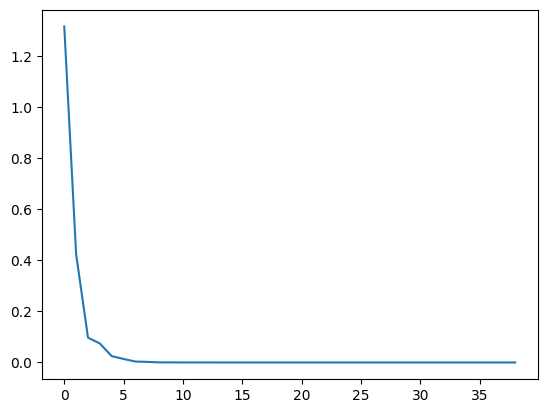

In [26]:
plt.plot(Distancias)

In [27]:
r

array([ 0.83319658,  0.05494366, -0.52136141])